<a href="https://colab.research.google.com/github/iswabwwwla/Informatica-aplicada-a-logistica/blob/main/RL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sakshisatre/ice-cream-sales-dataset")

print("Path to dataset files:", path)

100%|██████████| 2.09k/2.09k [00:00<00:00, 1.61MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/sakshisatre/ice-cream-sales-dataset/versions/1


In [2]:
import os
import pandas as pd

# Listar todos os arquivos no diretório baixado
files = os.listdir(path)
print("Arquivos encontrados:", files)

# Encontrar o primeiro arquivo CSV disponível
csv_files = [f for f in files if f.endswith('.csv')]

if csv_files:
    csv_path = os.path.join(path, csv_files[0])
    df = pd.read_csv(csv_path)
    print(f"DataFrame carregado com sucesso a partir de: {csv_files[0]}")
    display(df.head())
else:
    print("Nenhum arquivo CSV encontrado diretamente. Verificando subpastas...")
    # Busca recursiva simples se houver subpastas
    for root, dirs, filenames in os.walk(path):
        for f in filenames:
            if f.endswith('.csv'):
                csv_path = os.path.join(root, f)
                df = pd.read_csv(csv_path)
                print(f"DataFrame carregado com sucesso de: {csv_path}")
                display(df.head())
                break

Arquivos encontrados: ['Ice Cream.csv']
DataFrame carregado com sucesso a partir de: Ice Cream.csv


,Temperature,Revenue
0,24.6,535
1,26.1,626
2,27.8,661
3,20.6,488
4,11.6,317


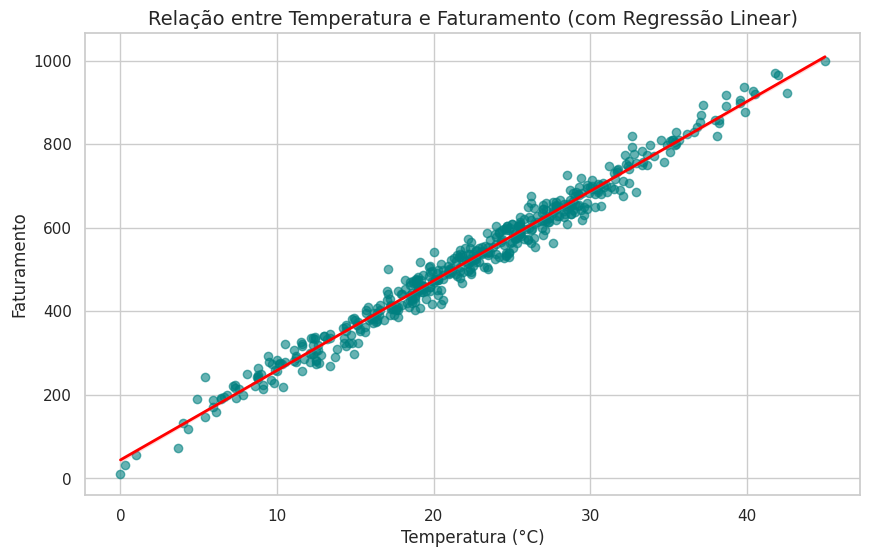

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar o estilo do gráfico
sns.set_theme(style="whitegrid")

# Criar a figura
plt.figure(figsize=(10, 6))

# Gerar o gráfico de dispersão com a linha de regressão linear
sns.regplot(data=df, x='Temperature', y='Revenue', scatter_kws={'alpha':0.6, 'color':'teal'}, line_kws={'color':'red', 'linewidth':2})

# Configurar títulos e rótulos
plt.title('Relação entre Temperatura e Faturamento (com Regressão Linear)', fontsize=14)
plt.xlabel('Temperatura (°C)', fontsize=12)
plt.ylabel('Faturamento', fontsize=12)

# Exibir o gráfico
plt.show()

In [4]:
from sklearn.linear_model import LinearRegression

# Preparar os dados para o modelo
X = df[['Temperature']]
y = df['Revenue']

# Inicializar e ajustar o modelo
model = LinearRegression()
model.fit(X, y)

# Obter os coeficientes
coef_angular = model.coef_[0]
intercepto = model.intercept_
r2 = model.score(X, y)

print(f"Coeficiente Angular (Inclinação): {coef_angular:.4f}")
print(f"Coeficiente Linear (Intercepto): {intercepto:.4f}")
print(f"Coeficiente de Determinação (R²): {r2:.4f}")
print(f"\nEquação da reta: Faturamento = {coef_angular:.2f} * Temperatura + ({intercepto:.2f})")

Coeficiente Angular (Inclinação): 21.4420
Coeficiente Linear (Intercepto): 44.2968
Coeficiente de Determinação (R²): 0.9798

Equação da reta: Faturamento = 21.44 * Temperatura + (44.30)
